In [1]:
!pip -q install scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
import random
import numpy as np

random.seed(42); np.random.seed(42)

vocab = {
    "invoice":  "invoice amount total tax payment due bill customer quantity price gst receipt paid balance order item subtotal".split(),
    "resume":   "experience skills education project university degree responsibilities worked developed team python java internship certification objective".split(),
    "research": "abstract method results dataset model experiment accuracy proposed analysis baseline algorithm training evaluation paper approach".split(),
    "legal":    "agreement party clause hereby liability terms jurisdiction contract court rights obligation notice breach indemnity witness".split(),
    "news":     "government minister announced police city report market match players election said yesterday officials public".split(),
}
common = "the of and to in is for on with as by at from this that are was be".split()
headers = {"invoice": "invoice no", "resume": "curriculum vitae", "research": "abstract",
           "legal": "this agreement", "news": "breaking news"}
classes = list(vocab)

def make_page(cls, first=False):
    n = random.randint(50, 80)
    words = [random.choice(vocab[cls]) if random.random() < 0.42 else random.choice(common) for _ in range(n)]
    if random.random() < 0.6:                                    # noise words from another class
        words += random.choices(vocab[random.choice(classes)], k=14)
    random.shuffle(words)
    if first and random.random() < 0.8:                          # most first pages carry a header
        words = headers[cls].split() + words
    return " ".join(words)

def make_stream(n_docs):
    """Returns pages, per-page class, per-page boundary flag (1 = first page of a document), doc ids."""
    pages, cls_lab, bnd, doc_id = [], [], [], []
    for d in range(n_docs):
        c = random.choice(classes)
        for j in range(random.randint(2, 5)):
            pages.append(make_page(c, first=(j == 0)))
            cls_lab.append(c); bnd.append(1 if j == 0 else 0); doc_id.append(d)
    return pages, cls_lab, bnd, doc_id

In [4]:
# Three independent streams: (A) train page classifier, (B) train boundary model, (C) test
pagesA, clsA, _, _ = make_stream(300)
pagesB, clsB, bndB, _ = make_stream(300)
pagesC, clsC, bndC, docC = make_stream(150)
print("Pages A/B/C:", len(pagesA), len(pagesB), len(pagesC), "| test documents:", max(docC) + 1)

Pages A/B/C: 1031 1065 524 | test documents: 150


In [5]:
# ---------- Feature extraction for the probabilistic model ----------
page_clf = make_pipeline(TfidfVectorizer(sublinear_tf=True), LogisticRegression(max_iter=1000)).fit(pagesA, clsA)
tfidf = page_clf.named_steps["tfidfvectorizer"]

def features(pages):
    X = tfidf.transform(pages)
    P = page_clf.predict_proba(pages)                      # class distribution of every page
    feats = [[0, 0, 1]]                                    # first page: handled by the FSM start state
    for i in range(1, len(pages)):
        sim = cosine_similarity(X[i], X[i-1])[0, 0]
        tv = 0.5 * np.abs(P[i] - P[i-1]).sum()             # change in class distribution
        has_header = float(any(pages[i].startswith(h) for h in headers.values()))
        feats.append([sim, tv, has_header])
    return np.array(feats)

FB, FC = features(pagesB), features(pagesC)
print("Feature matrix (test):", FC.shape, "-> [similarity, class-distribution change, header flag]")

Feature matrix (test): (524, 3) -> [similarity, class-distribution change, header flag]


In [6]:
# ---------- Probabilistic part: P(boundary | page features) ----------
boundary_model = LogisticRegression(C=5, max_iter=1000).fit(FB[1:], bndB[1:])
p_boundary = boundary_model.predict_proba(FC)[:, 1]
p_boundary[0] = 1.0

def prf(y_true, y_pred):
    y_true, y_pred = np.array(y_true[1:]), np.array(y_pred[1:])
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0
    return round(p, 3), round(r, 3), round(2 * p * r / (p + r), 3) if p + r else 0

pred_sim = [1] + [int(FC[i, 0] < 0.25) for i in range(1, len(pagesC))]           # baseline 1: similarity threshold
pred_prob = [1] + [int(p_boundary[i] > 0.5) for i in range(1, len(pagesC))]      # baseline 2: probabilistic only

In [7]:
# ---------- FSM part ----------
# States : B = first page of a document, I = continuation page of the same document
# Rules  : (1) the stream must start in B      (2) every document has at least 2 pages -> B cannot follow B
#          (3) I can follow B or I             (4) B can follow I
# Allowed transitions (1 = allowed):
#            to I  to B
#   from I     1     1
#   from B     1     0
STATES = ["I", "B"]
allowed = np.array([[1, 1],
                    [1, 0]])

# Transition probabilities learned from the training stream, then masked by the FSM
tags = np.array(bndB)
counts = np.ones((2, 2))                                   # Laplace smoothing
for a, b in zip(tags[:-1], tags[1:]): counts[a, b] += 1
trans = counts / counts.sum(axis=1, keepdims=True)
trans = trans * allowed
trans = trans / trans.sum(axis=1, keepdims=True)
print("Learned + FSM-masked transition matrix (rows: from I, B | cols: to I, B):")
print(pd.DataFrame(trans, index=["from I", "from B"], columns=["to I", "to B"]).round(3))

Learned + FSM-masked transition matrix (rows: from I, B | cols: to I, B):
         to I   to B
from I  0.608  0.392
from B  1.000  0.000


In [8]:
# ---------- Hybrid decoder: Viterbi over the FSM using the probabilistic scores ----------
def viterbi(p_b):
    eps = 1e-9
    T = len(p_b)
    emit = np.log(np.vstack([1 - p_b, p_b]).T + eps)       # columns: [I, B]
    logT = np.log(trans + eps)
    score = np.full((T, 2), -np.inf); back = np.zeros((T, 2), dtype=int)
    score[0, 1] = emit[0, 1]                                # rule (1): start in B
    for t in range(1, T):
        for s in range(2):
            cand = score[t-1] + logT[:, s]
            back[t, s] = cand.argmax()
            score[t, s] = cand.max() + emit[t, s]
    path = [int(score[-1].argmax())]
    for t in range(T - 1, 0, -1):
        path.append(int(back[t, path[-1]]))
    return path[::-1]

pred_hybrid = viterbi(p_boundary)

,method,precision,recall,F1
0,Similarity threshold,1.000,0.564,0.721
1,Probabilistic only (logistic regression),0.980,0.973,0.976
2,Hybrid: probabilistic + FSM (Viterbi),0.993,0.973,0.983


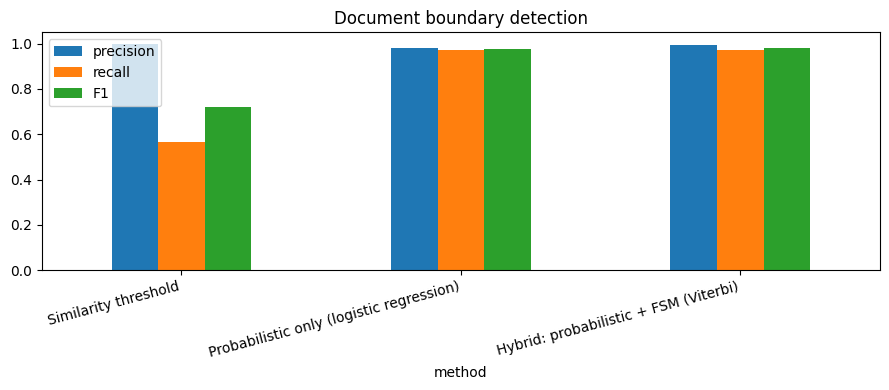

In [9]:
# ---------- Comparison ----------
res = pd.DataFrame([("Similarity threshold", *prf(bndC, pred_sim)),
                    ("Probabilistic only (logistic regression)", *prf(bndC, pred_prob)),
                    ("Hybrid: probabilistic + FSM (Viterbi)", *prf(bndC, pred_hybrid))],
                   columns=["method", "precision", "recall", "F1"])
display(res)

res.set_index("method")[["precision", "recall", "F1"]].plot(kind="bar", figsize=(9, 4), ylim=(0, 1.05))
plt.xticks(rotation=15, ha="right"); plt.title("Document boundary detection"); plt.tight_layout(); plt.show()

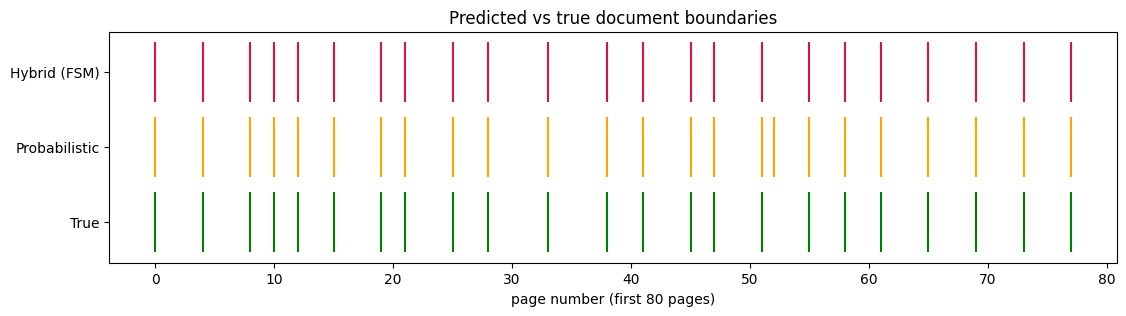

Mistakes corrected by the FSM constraints: 2 | e.g. pages [52, 333]


In [10]:
# ---------- Visualise boundaries ----------
show = slice(0, 80)
fig, ax = plt.subplots(figsize=(13, 3))
for row, (name, arr, col) in enumerate([("True", bndC, "green"), ("Probabilistic", pred_prob, "orange"),
                                        ("Hybrid (FSM)", pred_hybrid, "crimson")]):
    idx = [i for i, b in enumerate(arr[show]) if b]
    ax.vlines(idx, row, row + 0.8, colors=col)
ax.set_yticks([0.4, 1.4, 2.4]); ax.set_yticklabels(["True", "Probabilistic", "Hybrid (FSM)"])
ax.set_xlabel("page number (first 80 pages)"); plt.title("Predicted vs true document boundaries"); plt.show()

# Pages where the hybrid model fixed a probabilistic mistake
fixed = [i for i in range(1, len(pagesC)) if pred_prob[i] != bndC[i] and pred_hybrid[i] == bndC[i]]
print("Mistakes corrected by the FSM constraints:", len(fixed), "| e.g. pages", fixed[:8])